# Deep Learning – Assignment 4, Task 2
## Spoken Arabic Digit classification from pre-computed MFCC sequences (RNN / LSTM / GRU)

**Dataset:** UCI *Spoken Arabic Digit* (`Train_Arabic_Digit.txt`, `Test_Arabic_Digit.txt`) – each utterance is a variable-length sequence (4–93 frames) of 13-dim MFCC vectors, 10 classes (digits 0–9).

**Steps**
1. Parse the text files into utterances and labels, visualise MFCC heatmaps
2. Train / validation / test split, feature standardisation, padding + packing collation
3. Configurable recurrent classifier (Vanilla RNN / LSTM / GRU, layers, hidden units, optional bidirectional + attention pooling)
4. Convergence-based training: stop when |L̄(k) − L̄(k−1)| < 1e-4
5. Hyperparameter grid, training-error plots, summary tables
6. Best model: metrics + confusion matrix
7. Bonus: bidirectional / attention pooling
8. Gradient-flow analysis and comparative observations

> Place `Train_Arabic_Digit.txt` and `Test_Arabic_Digit.txt` next to this notebook (or set `DATA_DIR` below).

In [1]:
import os, glob, time, random, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

# ---------------- configuration ----------------
DATA_DIR      = '/content/'       # folder containing the two .txt files
SEED          = 42
BATCH_SIZE    = 64
LR            = 1e-3
TOL           = 1e-4       # convergence threshold on |L(k) - L(k-1)|
MAX_EPOCHS    = 150        # safety cap only; the real stopping rule is the TOL criterion
GRAD_CLIP     = 1.0
VAL_FRACTION  = 0.10
CELLS         = ["RNN", "LSTM", "GRU"]
LAYERS_GRID   = [1, 2]
HIDDEN_GRID   = [32, 64, 128]
FIG_DIR       = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


## 1. Load the MFCC sequences

In [2]:
def find_file(kind):
    pats = [f"{kind}*Arabic*Digit*.txt", f"{kind.lower()}*arabic*digit*.txt"]
    for p in pats:
        hits = glob.glob(os.path.join(DATA_DIR, p))
        if hits:
            return hits[0]
    raise FileNotFoundError(f"Could not find the {kind} file in '{DATA_DIR}'. "
                            "Download from https://archive.ics.uci.edu/dataset/195/spoken+arabic+digit")

def load_arabic(path):
    """Utterances are blocks of 13-number lines separated by a blank line."""
    utts, cur = [], []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line:
                if cur:
                    utts.append(np.asarray(cur, dtype=np.float32)); cur = []
            else:
                cur.append([float(v) for v in line.split()])
    if cur:
        utts.append(np.asarray(cur, dtype=np.float32))
    return utts

train_path, test_path = find_file("Train"), find_file("Test")
train_utts = load_arabic(train_path)
test_utts  = load_arabic(test_path)

# In the UCI files the utterances are ordered by digit (660 per digit in train, 220 in test)
y_train_all = np.repeat(np.arange(10), len(train_utts) // 10)
y_test      = np.repeat(np.arange(10), len(test_utts) // 10)
assert len(y_train_all) == len(train_utts) and len(y_test) == len(test_utts), "unexpected utterance counts"

lens = np.array([len(u) for u in train_utts + test_utts])
print(f"train utterances: {len(train_utts)}   test utterances: {len(test_utts)}")
print(f"feature dim: {train_utts[0].shape[1]}   sequence length min/mean/max: {lens.min()}/{lens.mean():.1f}/{lens.max()}")
print("train class counts:", np.bincount(y_train_all))
print("test  class counts:", np.bincount(y_test))

train utterances: 6600   test utterances: 2200
feature dim: 13   sequence length min/mean/max: 4/39.8/93
train class counts: [660 660 660 660 660 660 660 660 660 660]
test  class counts: [220 220 220 220 220 220 220 220 220 220]


## 2. Qualitative visualisation – MFCC heatmaps (coefficients × time)

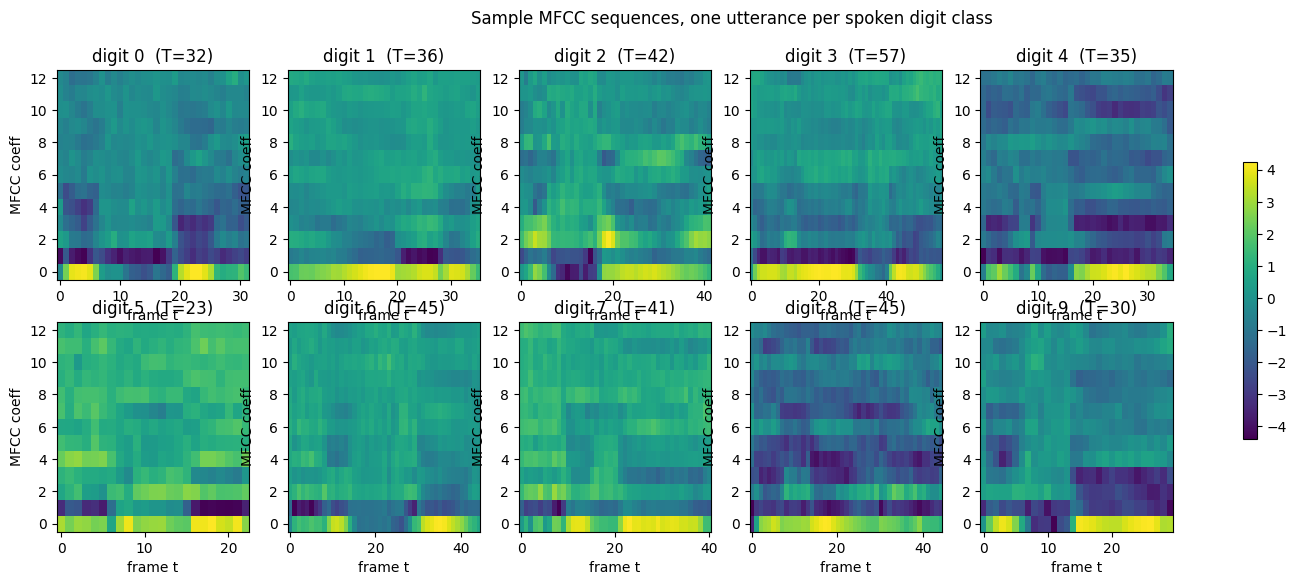

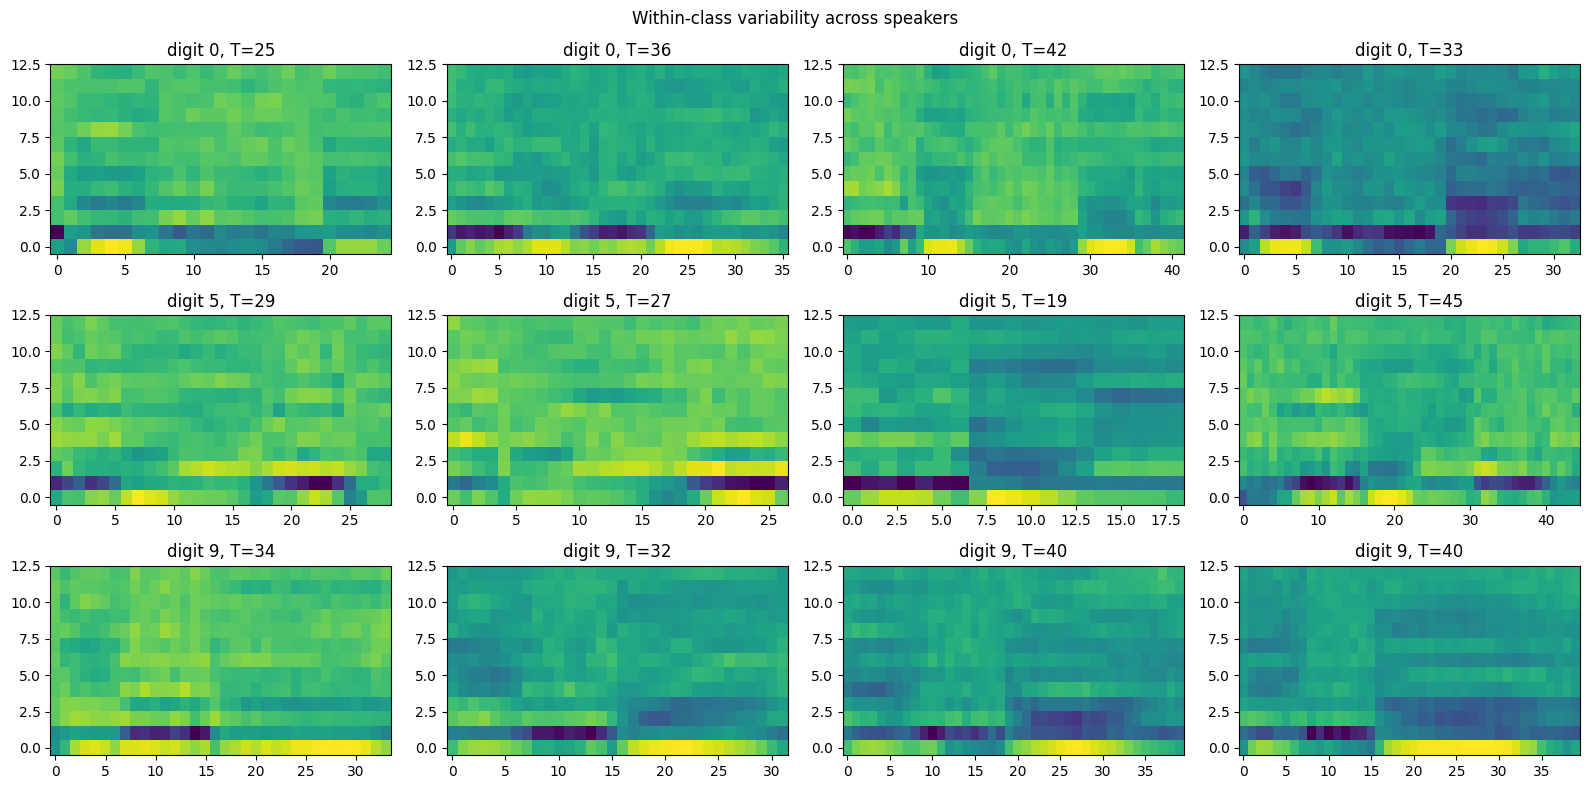

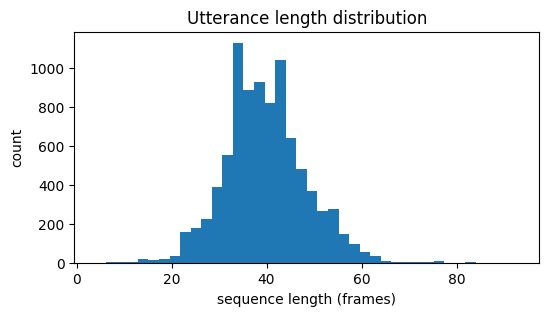

In [3]:
rng = np.random.RandomState(0)
fig, axes = plt.subplots(2, 5, figsize=(18, 6))
for d, ax in enumerate(axes.ravel()):
    idx = rng.choice(np.where(y_train_all == d)[0])
    u = train_utts[idx]
    im = ax.imshow(u.T, aspect="auto", origin="lower", cmap="viridis")
    ax.set_title(f"digit {d}  (T={len(u)})"); ax.set_xlabel("frame t"); ax.set_ylabel("MFCC coeff")
fig.colorbar(im, ax=axes, shrink=0.6)
plt.suptitle("Sample MFCC sequences, one utterance per spoken digit class")
plt.savefig(f"{FIG_DIR}/mfcc_heatmaps.png", dpi=150, bbox_inches="tight"); plt.show()

# Several different speakers for a few classes
fig, axes = plt.subplots(3, 4, figsize=(16, 8))
for r, d in enumerate([0, 5, 9]):
    for c in range(4):
        idx = rng.choice(np.where(y_train_all == d)[0])
        axes[r, c].imshow(train_utts[idx].T, aspect="auto", origin="lower", cmap="viridis")
        axes[r, c].set_title(f"digit {d}, T={len(train_utts[idx])}")
plt.suptitle("Within-class variability across speakers"); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/mfcc_heatmaps_variability.png", dpi=150, bbox_inches="tight"); plt.show()

plt.figure(figsize=(6,3)); plt.hist(lens, bins=40); plt.xlabel("sequence length (frames)"); plt.ylabel("count")
plt.title("Utterance length distribution"); plt.show()

## 3. Splits, standardisation, padding/packing collation

In [4]:
# train / validation split (stratified) from the official train file; official test file is the held-out test set
idx_all = np.arange(len(train_utts))
tr_idx, va_idx = train_test_split(idx_all, test_size=VAL_FRACTION, stratify=y_train_all, random_state=SEED)

# standardise each MFCC coefficient with statistics from the TRAINING frames only
tr_frames = np.concatenate([train_utts[i] for i in tr_idx], axis=0)
mu, sd = tr_frames.mean(0), tr_frames.std(0) + 1e-8
norm = lambda u: (u - mu) / sd

class MFCCDataset(Dataset):
    def __init__(self, utts, labels):
        self.x = [torch.from_numpy(norm(u)) for u in utts]
        self.y = torch.as_tensor(labels, dtype=torch.long)
    def __len__(self): return len(self.x)
    def __getitem__(self, i): return self.x[i], self.y[i]

def collate(batch):
    xs, ys = zip(*batch)
    lengths = torch.tensor([len(x) for x in xs], dtype=torch.long)
    return pad_sequence(xs, batch_first=True), lengths, torch.stack(ys)   # (B,T_max,13), (B,), (B,)

ds_train = MFCCDataset([train_utts[i] for i in tr_idx], y_train_all[tr_idx])
ds_val   = MFCCDataset([train_utts[i] for i in va_idx], y_train_all[va_idx])
ds_test  = MFCCDataset(test_utts, y_test)

g = torch.Generator(); g.manual_seed(SEED)
train_loader = DataLoader(ds_train, batch_size=BATCH_SIZE, shuffle=True,  collate_fn=collate, generator=g)
# unshuffled loaders for evaluation
train_eval_loader = DataLoader(ds_train, batch_size=256, shuffle=False, collate_fn=collate)
val_loader  = DataLoader(ds_val,  batch_size=256, shuffle=False, collate_fn=collate)
test_loader = DataLoader(ds_test, batch_size=256, shuffle=False, collate_fn=collate)
print(f"train {len(ds_train)} | val {len(ds_val)} | test {len(ds_test)}")

train 5940 | val 660 | test 2200


## 4. Model
A recurrent encoder (Vanilla RNN / LSTM / GRU) over the **packed** padded sequence, so padding frames never influence the hidden state.
The sequence summary is the last valid hidden state of the top layer (concatenating both directions if bidirectional), or optionally a **temporal attention pooling** over all valid timesteps (bonus). A linear layer gives the 10 class logits.

In [5]:
class SeqClassifier(nn.Module):
    def __init__(self, cell="LSTM", input_size=13, hidden=64, layers=1,
                 bidirectional=False, attention=False, n_classes=10):
        super().__init__()
        self.cell, self.bidir, self.attention = cell, bidirectional, attention
        rnn_cls = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[cell]
        self.rnn = rnn_cls(input_size, hidden, num_layers=layers, batch_first=True,
                           bidirectional=bidirectional)
        d = hidden * (2 if bidirectional else 1)
        if attention:
            self.att = nn.Sequential(nn.Linear(d, d), nn.Tanh(), nn.Linear(d, 1))
        self.fc = nn.Linear(d, n_classes)

    def forward(self, x, lengths):
        T = x.size(1)
        packed = pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        out_packed, h = self.rnn(packed)
        if self.attention:
            out, _ = pad_packed_sequence(out_packed, batch_first=True, total_length=T)   # (B,T,d)
            mask = torch.arange(T, device=x.device)[None, :] < lengths.to(x.device)[:, None]
            scores = self.att(out).squeeze(-1).masked_fill(~mask, float("-inf"))
            w = torch.softmax(scores, dim=1)
            feat = (w.unsqueeze(-1) * out).sum(1)
        else:
            if self.cell == "LSTM":
                h = h[0]                                      # (layers*dirs, B, H)
            feat = torch.cat([h[-2], h[-1]], dim=1) if self.bidir else h[-1]
        return self.fc(feat)

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)
print(SeqClassifier("LSTM", hidden=64, layers=2))

SeqClassifier(
  (rnn): LSTM(13, 64, num_layers=2, batch_first=True)
  (fc): Linear(in_features=64, out_features=10, bias=True)
)


## 5. Training with the convergence criterion
Training stops when the absolute difference between the average training loss of successive epochs drops below `1e-4`:

$$|\bar L^{(k)} - \bar L^{(k-1)}| < 10^{-4}$$

`MAX_EPOCHS` is only a safety cap so that a noisy run cannot loop forever. We also record the mean (pre-clipping) gradient norm of each epoch for the gradient-flow analysis.

In [6]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    preds, labels, loss_sum, n = [], [], 0.0, 0
    crit = nn.CrossEntropyLoss(reduction="sum")
    for x, l, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x, l)
        loss_sum += crit(logits, y).item(); n += len(y)
        preds.append(logits.argmax(1).cpu()); labels.append(y.cpu())
    preds, labels = torch.cat(preds).numpy(), torch.cat(labels).numpy()
    return (preds == labels).mean(), loss_sum / n, preds, labels

def train_model(cell, layers, hidden, bidirectional=False, attention=False, verbose=False):
    set_seed()
    model = SeqClassifier(cell, 13, hidden, layers, bidirectional, attention).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    crit = nn.CrossEntropyLoss()
    losses, gnorms, val_accs = [], [], []
    t0 = time.time()
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        run_loss, run_g, nb = 0.0, 0.0, 0
        for x, l, y in train_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            loss = crit(model(x, l), y)
            loss.backward()
            run_g += torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP).item()
            opt.step()
            run_loss += loss.item(); nb += 1
        losses.append(run_loss / nb); gnorms.append(run_g / nb)
        val_accs.append(evaluate(model, val_loader)[0])
        if verbose:
            print(f"epoch {epoch:3d} loss {losses[-1]:.4f} val_acc {val_accs[-1]:.4f}")
        if epoch > 1 and abs(losses[-1] - losses[-2]) < TOL:      # convergence criterion
            break
    tr_acc = evaluate(model, train_eval_loader)[0]
    va_acc = evaluate(model, val_loader)[0]
    te_acc = evaluate(model, test_loader)[0]
    return dict(name=f"{cell}-L{layers}-H{hidden}" + ("-Bi" if bidirectional else "") + ("-Attn" if attention else ""),
                cell=cell, layers=layers, hidden=hidden, bidir=bidirectional, attn=attention,
                params=count_params(model), epochs=len(losses), converged=len(losses) < MAX_EPOCHS,
                losses=losses, gnorms=gnorms, val_accs=val_accs,
                train_acc=tr_acc, val_acc=va_acc, test_acc=te_acc,
                time=time.time() - t0, model=model)

# quick sanity check (1 config, printed per epoch)
_ = train_model("GRU", 1, 32, verbose=True)
print({k: v for k, v in _.items() if k in ["name","epochs","converged","train_acc","val_acc","test_acc"]})

epoch   1 loss 2.0812 val_acc 0.3758
epoch   2 loss 1.4332 val_acc 0.6455
epoch   3 loss 0.9356 val_acc 0.7788
epoch   4 loss 0.6715 val_acc 0.8591
epoch   5 loss 0.4945 val_acc 0.9030
epoch   6 loss 0.3734 val_acc 0.9091
epoch   7 loss 0.2914 val_acc 0.9455
epoch   8 loss 0.2366 val_acc 0.9455
epoch   9 loss 0.1961 val_acc 0.9500
epoch  10 loss 0.1606 val_acc 0.9636
epoch  11 loss 0.1336 val_acc 0.9606
epoch  12 loss 0.1173 val_acc 0.9652
epoch  13 loss 0.0995 val_acc 0.9682
epoch  14 loss 0.0854 val_acc 0.9697
epoch  15 loss 0.0755 val_acc 0.9667
epoch  16 loss 0.0664 val_acc 0.9727
epoch  17 loss 0.0581 val_acc 0.9742
epoch  18 loss 0.0508 val_acc 0.9742
epoch  19 loss 0.0443 val_acc 0.9742
epoch  20 loss 0.0378 val_acc 0.9742
epoch  21 loss 0.0351 val_acc 0.9758
epoch  22 loss 0.0292 val_acc 0.9758
epoch  23 loss 0.0288 val_acc 0.9773
epoch  24 loss 0.0261 val_acc 0.9742
epoch  25 loss 0.0277 val_acc 0.9788
epoch  26 loss 0.0219 val_acc 0.9788
epoch  27 loss 0.0209 val_acc 0.9758
e

## 6. Hyperparameter study: cell type × #layers × #units

In [7]:
results = []
for cell in CELLS:
    for L in LAYERS_GRID:
        for H in HIDDEN_GRID:
            r = train_model(cell, L, H)
            results.append(r)
            print(f"{r['name']:14s} epochs={r['epochs']:3d} conv={r['converged']} "
                  f"train={r['train_acc']:.4f} val={r['val_acc']:.4f} test={r['test_acc']:.4f} ({r['time']:.0f}s)")

RNN-L1-H32     epochs=150 conv=False train=0.9606 val=0.9303 test=0.8650 (81s)
RNN-L1-H64     epochs= 26 conv=True train=0.9466 val=0.9273 test=0.8691 (14s)
RNN-L1-H128    epochs=150 conv=False train=0.9914 val=0.9773 test=0.9168 (81s)
RNN-L2-H32     epochs= 31 conv=True train=0.9239 val=0.9000 test=0.8314 (25s)
RNN-L2-H64     epochs=150 conv=False train=0.9904 val=0.9697 test=0.9241 (118s)
RNN-L2-H128    epochs=150 conv=False train=0.9971 val=0.9894 test=0.9459 (118s)
LSTM-L1-H32    epochs= 90 conv=True train=1.0000 val=0.9939 test=0.9532 (55s)
LSTM-L1-H64    epochs= 52 conv=True train=1.0000 val=0.9909 test=0.9568 (31s)
LSTM-L1-H128   epochs= 31 conv=True train=1.0000 val=0.9924 test=0.9750 (18s)
LSTM-L2-H32    epochs= 54 conv=True train=1.0000 val=0.9955 test=0.9573 (46s)
LSTM-L2-H64    epochs= 22 conv=True train=1.0000 val=0.9939 test=0.9582 (19s)
LSTM-L2-H128   epochs= 18 conv=True train=1.0000 val=0.9955 test=0.9618 (16s)
GRU-L1-H32     epochs= 28 conv=True train=0.9978 val=0.983

### 6a. Average training error vs. epochs (every hyperparameter set)

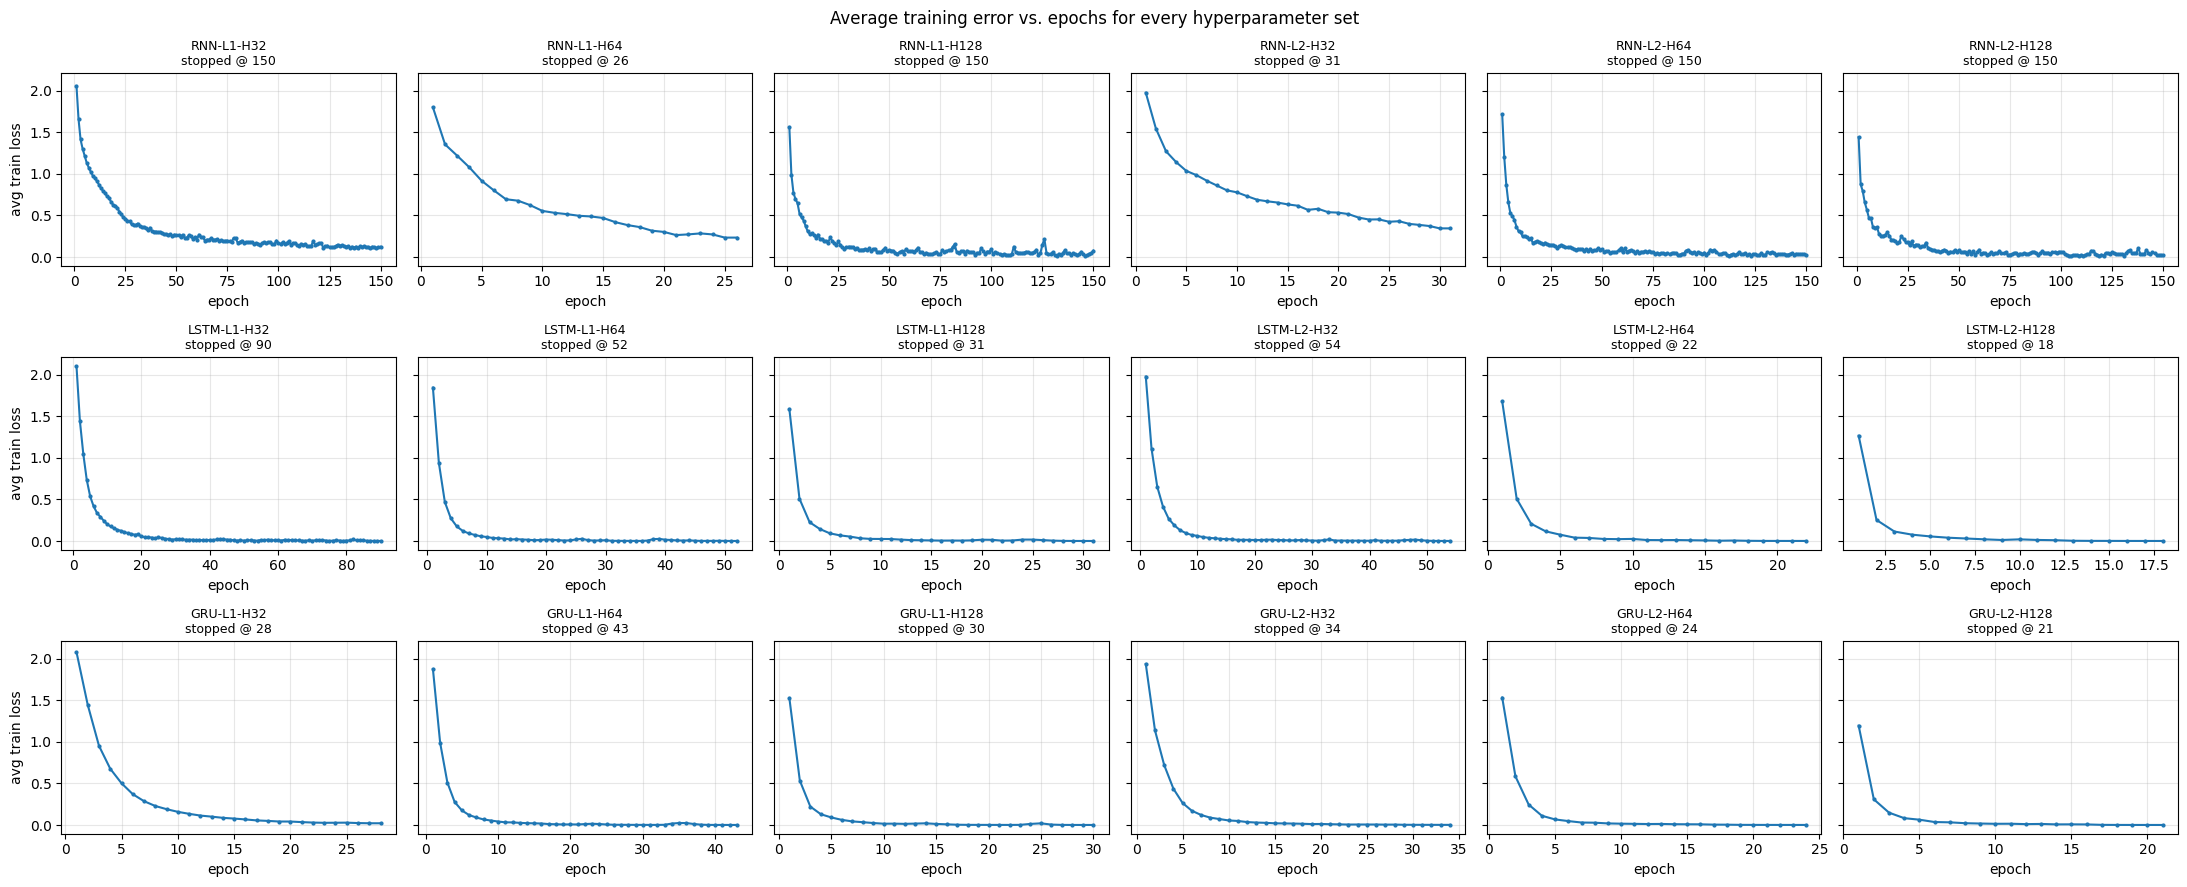

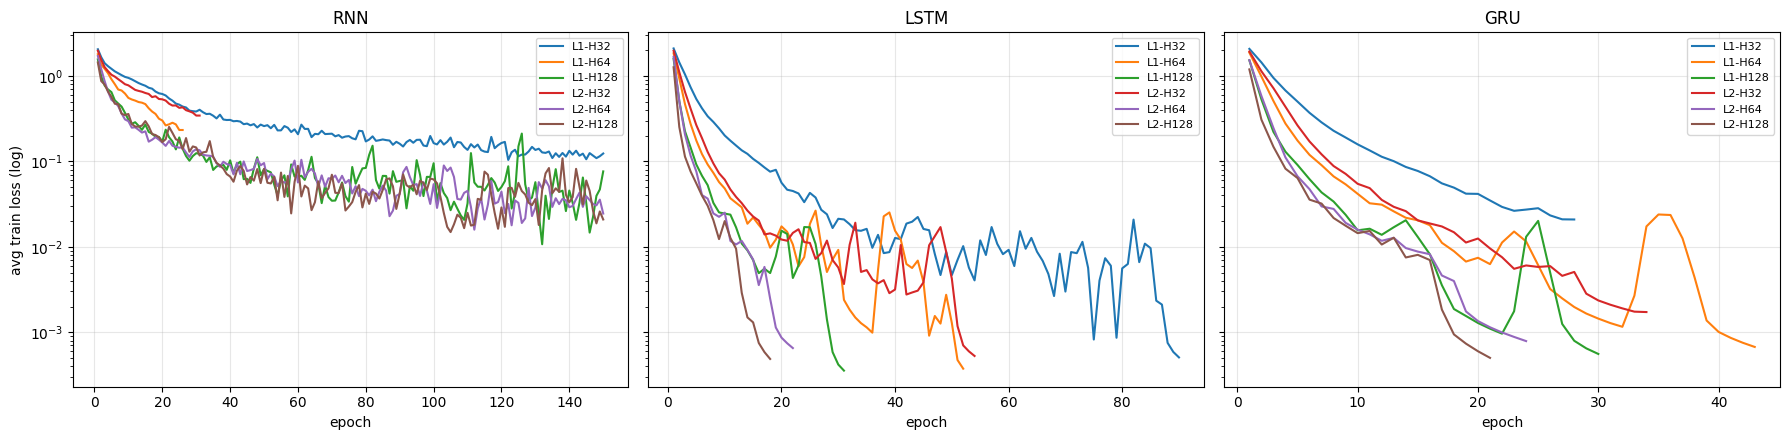

In [8]:
fig, axes = plt.subplots(len(CELLS), len(LAYERS_GRID) * len(HIDDEN_GRID), figsize=(22, 9), sharey=True)
for r_i, cell in enumerate(CELLS):
    for c_i, r in enumerate([r for r in results if r["cell"] == cell]):
        ax = axes[r_i, c_i]
        ax.plot(range(1, r["epochs"] + 1), r["losses"], marker="o", ms=2)
        ax.set_title(f"{r['name']}\nstopped @ {r['epochs']}", fontsize=9)
        ax.set_xlabel("epoch");
        if c_i == 0: ax.set_ylabel("avg train loss")
        ax.grid(alpha=.3)
plt.suptitle("Average training error vs. epochs for every hyperparameter set")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/loss_grid.png", dpi=150); plt.show()

# overlay per cell type for easy comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, cell in zip(axes, CELLS):
    for r in [r for r in results if r["cell"] == cell]:
        ax.plot(range(1, r["epochs"] + 1), r["losses"], label=f"L{r['layers']}-H{r['hidden']}")
    ax.set_title(cell); ax.set_xlabel("epoch"); ax.set_yscale("log"); ax.grid(alpha=.3); ax.legend(fontsize=8)
axes[0].set_ylabel("avg train loss (log)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/loss_overlay.png", dpi=150); plt.show()

### 6b. Summary table – training / validation / test accuracy

In [9]:
def to_df(res):
    return pd.DataFrame([{ "model": r["name"], "cell": r["cell"], "layers": r["layers"], "hidden": r["hidden"],
                           "params": r["params"], "epochs_to_converge": r["epochs"], "converged_by_tol": r["converged"],
                           "train_acc": round(r["train_acc"]*100, 2), "val_acc": round(r["val_acc"]*100, 2),
                           "test_acc": round(r["test_acc"]*100, 2), "final_train_loss": round(r["losses"][-1], 4),
                           "time_s": round(r["time"], 1)} for r in res])
df = to_df(results)
df.to_csv("task2_hyperparameter_results.csv", index=False)
display(df)
print("\nBest per cell type (selected on validation accuracy):")
display(df.loc[df.groupby("cell")["val_acc"].idxmax()])

,model,cell,layers,hidden,params,epochs_to_converge,converged_by_tol,train_acc,val_acc,test_acc,final_train_loss,time_s
0,RNN-L1-H32,RNN,1,32,1834,150,False,96.06,93.03,86.50,0.1238,81.2
1,RNN-L1-H64,RNN,1,64,5706,26,True,94.66,92.73,86.91,0.2334,14.1
2,RNN-L1-H128,RNN,1,128,19594,150,False,99.14,97.73,91.68,0.0764,81.0
3,RNN-L2-H32,RNN,2,32,3946,31,True,92.39,90.00,83.14,0.3445,24.6
4,RNN-L2-H64,RNN,2,64,14026,150,False,99.04,96.97,92.41,0.0245,117.5
5,RNN-L2-H128,RNN,2,128,52618,150,False,99.71,98.94,94.59,0.0209,118.3
6,LSTM-L1-H32,LSTM,1,32,6346,90,True,100.00,99.39,95.32,0.0005,55.2
7,LSTM-L1-H64,LSTM,1,64,20874,52,True,100.00,99.09,95.68,0.0004,31.1
8,LSTM-L1-H128,LSTM,1,128,74506,31,True,100.00,99.24,97.50,0.0004,18.4
9,LSTM-L2-H32,LSTM,2,32,14794,54,True,100.00,99.55,95.73,0.0005,45.5



Best per cell type (selected on validation accuracy):


,model,cell,layers,hidden,params,epochs_to_converge,converged_by_tol,train_acc,val_acc,test_acc,final_train_loss,time_s
15,GRU-L2-H32,GRU,2,32,11178,34,True,99.88,99.39,95.73,0.0017,27.5
9,LSTM-L2-H32,LSTM,2,32,14794,54,True,100.00,99.55,95.73,0.0005,45.5
5,RNN-L2-H128,RNN,2,128,52618,150,False,99.71,98.94,94.59,0.0209,118.3


## 7. Best configuration – final metrics and confusion matrix
The best model is chosen on **validation** accuracy (not test accuracy) to avoid selecting on the held-out set.

Best overall: LSTM-L2-H32
final training accuracy: 100.00%   test accuracy: 95.73%   (epochs: 54)

              precision    recall  f1-score   support

           0     0.8683    0.9591    0.9114       220
           1     0.9954    0.9818    0.9886       220
           2     0.9552    0.9682    0.9616       220
           3     0.9447    0.9318    0.9382       220
           4     1.0000    0.9591    0.9791       220
           5     0.9362    1.0000    0.9670       220
           6     0.9949    0.8864    0.9375       220
           7     0.9330    0.9500    0.9414       220
           8     0.9952    0.9364    0.9649       220
           9     0.9692    1.0000    0.9843       220

    accuracy                         0.9573      2200
   macro avg     0.9592    0.9573    0.9574      2200
weighted avg     0.9592    0.9573    0.9574      2200



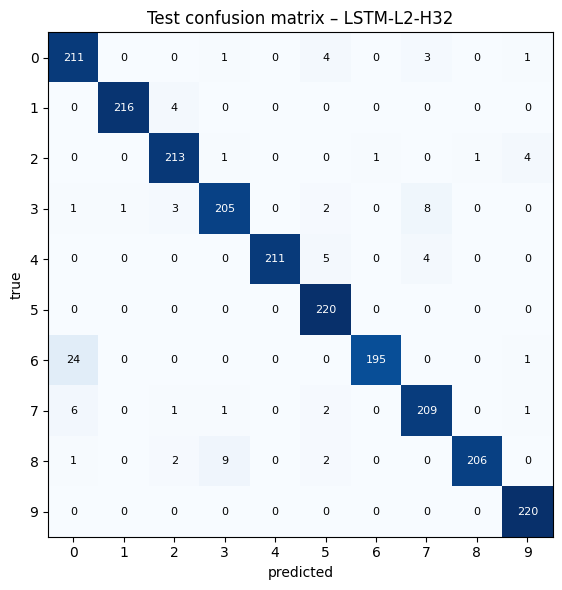

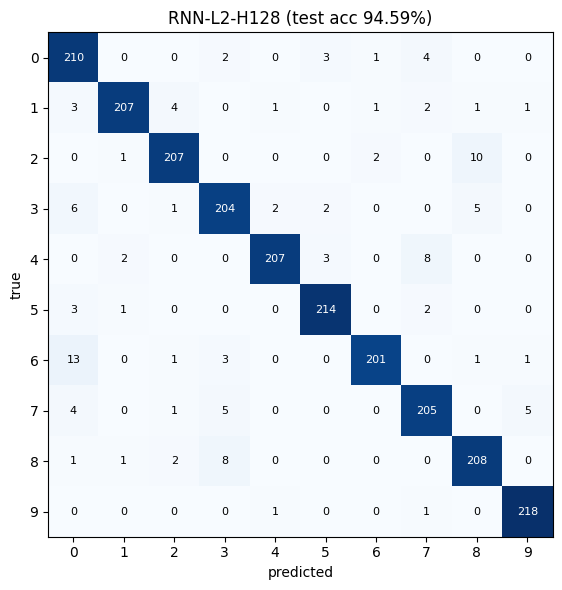

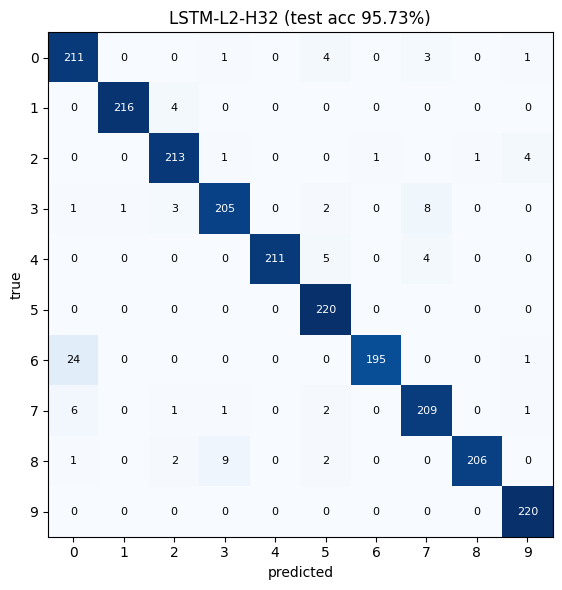

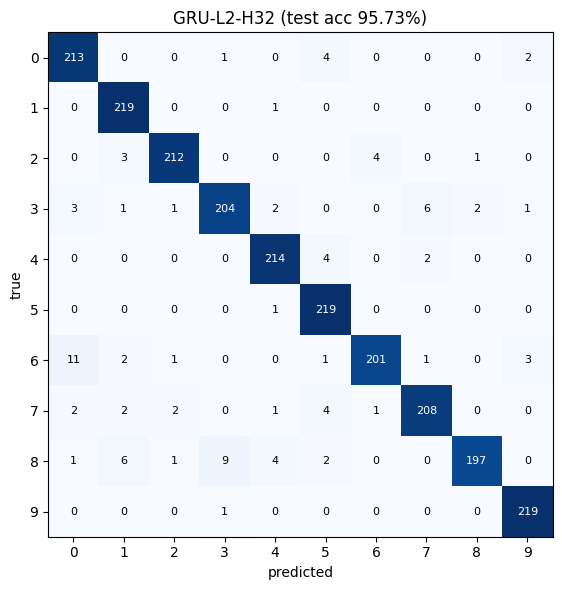

In [10]:
best = max(results, key=lambda r: r["val_acc"])
print("Best overall:", best["name"])
tr_acc, _, _, _ = evaluate(best["model"], train_eval_loader)
te_acc, te_loss, te_pred, te_true = evaluate(best["model"], test_loader)
print(f"final training accuracy: {tr_acc*100:.2f}%   test accuracy: {te_acc*100:.2f}%   (epochs: {best['epochs']})\n")
print(classification_report(te_true, te_pred, digits=4))

def plot_cm(y_true, y_pred, title, fname):
    cm = confusion_matrix(y_true, y_pred, labels=range(10))
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.imshow(cm, cmap="Blues")
    for i in range(10):
        for j in range(10):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=8)
    ax.set_xticks(range(10)); ax.set_yticks(range(10))
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/{fname}", dpi=150); plt.show()
    return cm

cm = plot_cm(te_true, te_pred, f"Test confusion matrix – {best['name']}", "confusion_best.png")

# also the best model of each cell type
for cell in CELLS:
    b = max([r for r in results if r["cell"] == cell], key=lambda r: r["val_acc"])
    _, _, p, t = evaluate(b["model"], test_loader)
    plot_cm(t, p, f"{b['name']} (test acc {b['test_acc']*100:.2f}%)", f"confusion_{cell}.png")

## 8. Bonus: bidirectional recurrence and temporal attention pooling
Starting from the best cell/depth/width found above, we test (i) bidirectional, (ii) attention pooling, (iii) both.

LSTM-L2-H32            epochs= 54 train=1.0000 val=0.9955 test=0.9573
LSTM-L2-H32-Bi         epochs= 24 train=1.0000 val=0.9924 test=0.9677
LSTM-L2-H32-Attn       epochs= 40 train=0.9995 val=0.9909 test=0.9627
LSTM-L2-H32-Bi-Attn    epochs= 16 train=0.9990 val=0.9955 test=0.9564


,model,cell,layers,hidden,params,epochs_to_converge,converged_by_tol,train_acc,val_acc,test_acc,final_train_loss,time_s
0,LSTM-L2-H32,LSTM,2,32,14794,54,True,100.00,99.55,95.73,0.0005,45.5
1,LSTM-L2-H32-Bi,LSTM,2,32,37770,24,True,100.00,99.24,96.77,0.0008,33.4
2,LSTM-L2-H32-Attn,LSTM,2,32,15883,40,True,99.95,99.09,96.27,0.0025,52.1
3,LSTM-L2-H32-Bi-Attn,LSTM,2,32,41995,16,True,99.90,99.55,95.64,0.0048,30.3


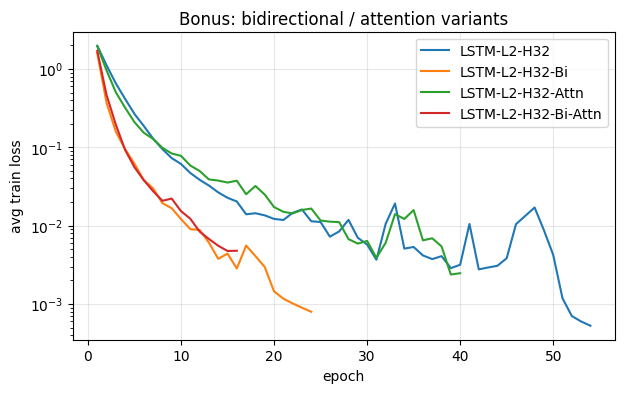

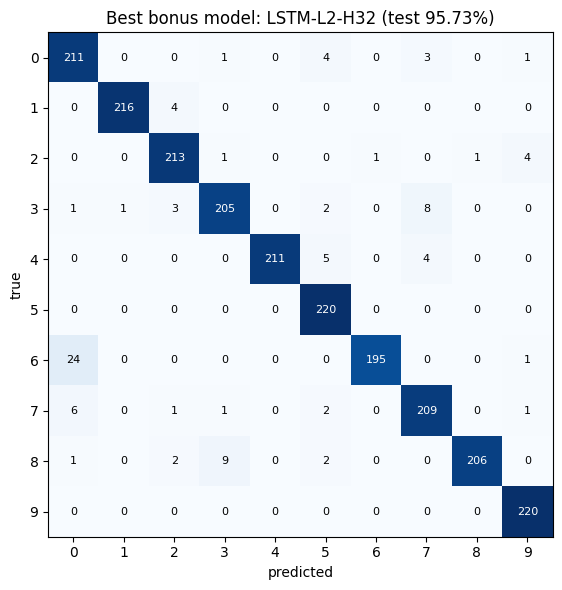

In [11]:
base = best
bonus = []
for bi, at in [(False, False), (True, False), (False, True), (True, True)]:
    r = base if (not bi and not at) else train_model(base["cell"], base["layers"], base["hidden"], bidirectional=bi, attention=at)
    bonus.append(r)
    print(f"{r['name']:22s} epochs={r['epochs']:3d} train={r['train_acc']:.4f} val={r['val_acc']:.4f} test={r['test_acc']:.4f}")
df_bonus = to_df(bonus); df_bonus.to_csv("task2_bonus_results.csv", index=False); display(df_bonus)

plt.figure(figsize=(7, 4))
for r in bonus: plt.plot(range(1, r["epochs"] + 1), r["losses"], label=r["name"])
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("avg train loss"); plt.legend(); plt.grid(alpha=.3)
plt.title("Bonus: bidirectional / attention variants"); plt.savefig(f"{FIG_DIR}/bonus_loss.png", dpi=150); plt.show()

best_bonus = max(bonus, key=lambda r: r["val_acc"])
_, _, p, t = evaluate(best_bonus["model"], test_loader)
_ = plot_cm(t, p, f"Best bonus model: {best_bonus['name']} (test {best_bonus['test_acc']*100:.2f}%)", "confusion_bonus.png")

## 9. Gradient-flow analysis
Two views:
1. **Training-time gradient norm** (mean pre-clipping global norm per epoch) for the best configuration of each cell type.
2. **Gradient reaching earlier timesteps:** the norm of ∂L/∂xₜ as a function of the distance *k* from the final timestep. A fast decay with *k* indicates vanishing gradients (the model cannot learn dependencies on early frames); gated cells (LSTM/GRU) are expected to decay more slowly than a vanilla RNN.

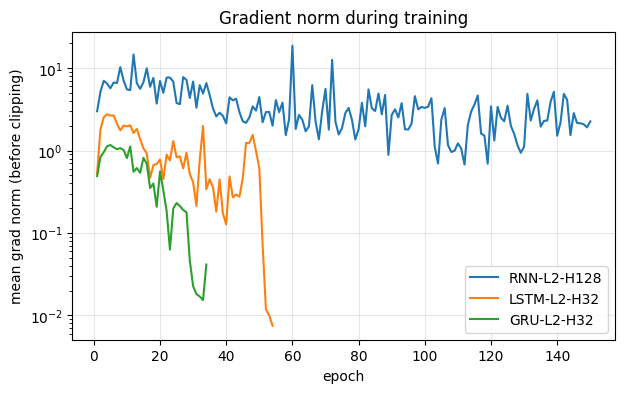

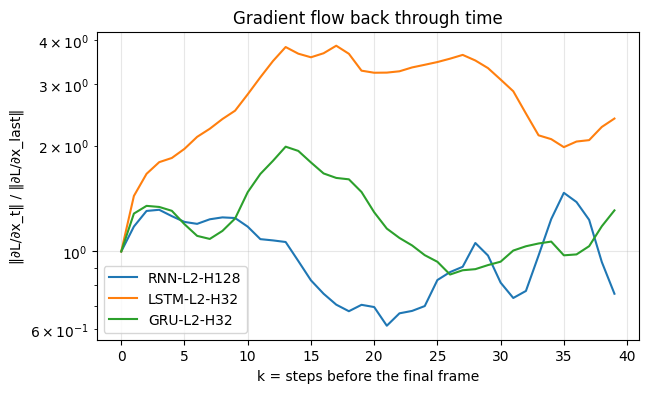

RNN   relative gradient at k=10: 1.177e+00   k=20: 6.944e-01   k=39: 7.578e-01
LSTM  relative gradient at k=10: 2.806e+00   k=20: 3.232e+00   k=39: 2.393e+00
GRU   relative gradient at k=10: 1.476e+00   k=20: 1.294e+00   k=39: 1.310e+00


In [12]:
best_per_cell = {c: max([r for r in results if r["cell"] == c], key=lambda r: r["val_acc"]) for c in CELLS}

# (1) gradient norm during training
plt.figure(figsize=(7, 4))
for c, r in best_per_cell.items():
    plt.plot(range(1, r["epochs"] + 1), r["gnorms"], label=r["name"])
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("mean grad norm (before clipping)")
plt.legend(); plt.grid(alpha=.3); plt.title("Gradient norm during training")
plt.savefig(f"{FIG_DIR}/grad_norm_training.png", dpi=150); plt.show()

# (2) input-gradient profile vs. distance from the last timestep
def input_grad_profile(model, loader, max_k=40, min_len=40):
    model.train()          # cuDNN RNN backward needs train mode (the model has no dropout/BN, so this is harmless)
    sums, counts = np.zeros(max_k), np.zeros(max_k)
    for x, l, y in loader:
        keep = l >= min_len
        if keep.sum() == 0: continue
        x, l, y = x[keep].to(device), l[keep], y[keep].to(device)
        x.requires_grad_(True)
        loss = nn.functional.cross_entropy(model(x, l), y, reduction="sum")
        model.zero_grad(); loss.backward()
        g = x.grad.norm(dim=2).cpu().numpy()               # (B, T)
        for b in range(g.shape[0]):
            T = int(l[b])
            for k in range(max_k):
                sums[k] += g[b, T - 1 - k]; counts[k] += 1
    return sums / np.maximum(counts, 1)

plt.figure(figsize=(7, 4))
profiles = {}
for c, r in best_per_cell.items():
    prof = input_grad_profile(r["model"], test_loader)
    profiles[c] = prof
    plt.plot(range(len(prof)), prof / prof[0], label=r["name"])
plt.yscale("log"); plt.xlabel("k = steps before the final frame"); plt.ylabel("‖∂L/∂x_t‖ / ‖∂L/∂x_last‖")
plt.legend(); plt.grid(alpha=.3); plt.title("Gradient flow back through time")
plt.savefig(f"{FIG_DIR}/grad_flow_time.png", dpi=150); plt.show()
for c, p in profiles.items():
    print(f"{c:5s} relative gradient at k=10: {p[10]/p[0]:.3e}   k=20: {p[20]/p[0]:.3e}   k=39: {p[39]/p[0]:.3e}")

## 10. Compact summary for the report

In [13]:
summary = df.groupby("cell").agg(best_test_acc=("test_acc", "max"), mean_test_acc=("test_acc", "mean"),
                                 mean_epochs=("epochs_to_converge", "mean"), mean_params=("params", "mean")).round(2)
display(summary)
print("Fraction of runs that met the 1e-4 criterion before the epoch cap:",
      f"{df['converged_by_tol'].mean()*100:.0f}%")
print(f"\nBest overall (baseline grid): {best['name']}  train {best['train_acc']*100:.2f}%  test {best['test_acc']*100:.2f}%")
print(f"Best overall (incl. bonus):   {best_bonus['name']}  test {best_bonus['test_acc']*100:.2f}%")

,best_test_acc,mean_test_acc,mean_epochs,mean_params
cell,,,,
GRU,96.82,95.72,30.0,47348.67
LSTM,97.50,96.04,44.5,62879.33
RNN,94.59,89.20,109.5,16287.33


Fraction of runs that met the 1e-4 criterion before the epoch cap: 78%

Best overall (baseline grid): LSTM-L2-H32  train 100.00%  test 95.73%
Best overall (incl. bonus):   LSTM-L2-H32  test 95.73%


## 11. Observations and analysis
*(Fill this in after running the notebook, using the plots/tables above – these are the points the assignment asks for.)*

- **Performance:** compare best test accuracy of Vanilla RNN vs LSTM vs GRU (table in §6b / §10); note the train–test gap (overfitting) and which classes are confused (§7 confusion matrices).
- **Effect of depth / width:** does a 2nd layer or more units help, and at what parameter cost?
- **Convergence behaviour:** epochs needed under the 1e-4 criterion, smoothness of the loss curves (§6a), and whether noisy runs hit the epoch cap.
- **Gradient flow:** compare gradient-norm curves (§9) and the decay of ∂L/∂xₜ with distance from the output; relate to vanishing gradients in the vanilla RNN and gating in LSTM/GRU.
- **Bonus:** effect of bidirectionality and attention pooling (§8) – attention/bidirectional models see the whole utterance rather than only the last state.